# 03 · Training a small CNN (empty vs. occupied)

**Goal:** train a small convolutional neural network (CNN) on one parking lot, then test it on a lot it has never seen.

The plan:
1. **Split** the patches: train on UFPR (UFPR04 + UFPR05), test on PUCPR.
2. **Validation set by day:** hold out the *last days* of UFPR footage, so validation photos aren't 5-minute near-copies of training photos.
3. **Build** a tiny CNN from scratch (3 layers of "pattern detectors").
4. **Train** it, keeping the version that scores best on validation.
5. **Test** on PUCPR once, at the very end, and look at the mistakes.

In [1]:
import csv
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image

random.seed(42)
torch.manual_seed(42)  # makes the starting weights the same every run, so results are repeatable

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Training on:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

Training on: NVIDIA GeForce RTX 5070


## 1. Split the data

- **Test = PUCPR.** Never used for training or for any decision, only for the final score.
- **Validation = the last 20% of days for each UFPR camera.** We use it to pick the best epoch.
  Splitting by *day* matters: if we split randomly, a validation photo taken at 9:05 would have a near-twin
  from 9:00 in training, and validation would look better than it really is (the same leakage problem from notebook 01).
- **Train = the rest of UFPR.**

In [2]:
with open("patches/index.csv") as f:
    rows = list(csv.DictReader(f))

train_rows, val_rows, test_rows = [], [], []

for camera in ["UFPR04", "UFPR05"]:
    camera_rows = [r for r in rows if r["camera"] == camera]
    days = sorted({r["date"] for r in camera_rows})
    cutoff = days[int(len(days) * 0.8)]  # first day of the last 20%
    train_rows += [r for r in camera_rows if r["date"] < cutoff]
    val_rows += [r for r in camera_rows if r["date"] >= cutoff]

test_rows = [r for r in rows if r["camera"] == "PUCPR"]

for name, split in [("train", train_rows), ("val", val_rows), ("test", test_rows)]:
    occupied = sum(r["label"] == "occupied" for r in split) / len(split)
    print(f"{name:5s}: {len(split):6d} patches, {occupied:.0%} occupied")

train:  53264 patches, 52% occupied
val  :  14736 patches, 55% occupied
test : 100000 patches, 43% occupied


## 2. Load the patches into memory

Reading 160,000+ small files from disk every epoch is slow. Instead we read each file **once** and keep them all
in one big array of numbers (about 2 GB of RAM). Each patch becomes a 3×64×64 grid: 3 color channels (red, green, blue),
64×64 pixels, each a number from 0 to 255.

Labels become numbers: **0 = empty, 1 = occupied**.

In [3]:
LABEL_TO_NUMBER = {"empty": 0, "occupied": 1}

def load_patches(split_rows):
    images = np.stack([np.array(Image.open(r["file"]).convert("RGB")) for r in split_rows])  # (N, 64, 64, 3)
    images = torch.from_numpy(images).permute(0, 3, 1, 2).contiguous()  # PyTorch wants (N, 3, 64, 64)
    labels = torch.tensor([LABEL_TO_NUMBER[r["label"]] for r in split_rows])
    return images, labels

X_train, y_train = load_patches(train_rows)
X_val, y_val = load_patches(val_rows)
X_test, y_test = load_patches(test_rows)
print("train:", tuple(X_train.shape), " val:", tuple(X_val.shape), " test:", tuple(X_test.shape))

train: (53264, 3, 64, 64)  val: (14736, 3, 64, 64)  test: (100000, 3, 64, 64)


## 3. Preparing a batch for the network

Two small steps every time the model sees a batch:
- **Scale pixels from 0–255 to roughly −1…1.** Neural networks train much more smoothly on small numbers.
- **Data augmentation (training only):** randomly flip patches left↔right and randomly brighten/darken them.
  A flipped empty spot is still empty, and PUCPR was filmed in a different season with different light.
  This teaches the model that brightness and direction *don't* decide the answer.

In [4]:
def prepare_batch(images, augment=False):
    x = images.to(device).float() / 255.0  # 0..1
    if augment:
        flip = torch.rand(x.shape[0], device=device) < 0.5
        x[flip] = x[flip].flip(dims=[3])  # mirror left-right
        brightness = 0.7 + 0.6 * torch.rand(x.shape[0], 1, 1, 1, device=device)  # x0.7 .. x1.3
        x = (x * brightness).clamp(0, 1)
    return (x - 0.5) / 0.5  # roughly -1..1

## 4. The model

A CNN slides small 3×3 "pattern detectors" (filters) across the image. Early layers find simple things (edges, color
blobs); later layers combine those into bigger things (a windshield, painted lines). Each **block** below is:

- `Conv2d`: learns the filters
- `BatchNorm2d`: keeps the numbers in a stable range so training doesn't go haywire
- `ReLU`: keeps positive signals, zeroes out negative ones (this is what lets the network learn non-straight-line patterns)
- `MaxPool2d`: shrinks the image by half, keeping the strongest signal in each 2×2 area

Image size through the network: **64×64 → 32×32 → 16×16 → 8×8**, while the number of filters grows 32 → 64 → 128.
At the end, `AdaptiveAvgPool2d` averages each filter's 8×8 map into one number, and `Linear` turns those 128 numbers
into 2 scores: one for *empty*, one for *occupied*.

In [5]:
def block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

model = nn.Sequential(
    block(3, 32),     # 64x64 -> 32x32
    block(32, 64),    # 32x32 -> 16x16
    block(64, 128),   # 16x16 -> 8x8
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Dropout(0.3),  # randomly ignore 30% of features while training, which reduces memorizing
    nn.Linear(128, 2),
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable numbers (parameters): {n_params:,}")

Sequential(
  (0): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (3): AdaptiveAvgPool2d(output_size=1)
  (4): Flatten(start_dim=1, end_dim=-1)
  (5): Dropou

## 5. Training

- **Loss = CrossEntropyLoss:** measures how wrong the 2 scores are. Training = nudging the parameters to shrink it.
- **Optimizer = Adam (learning rate 0.001):** the rule that does the nudging. A standard, reliable default.
- **Batch size 256:** the model looks at 256 patches, then updates once.
- **Epoch:** one full pass over the training set. We do 10.
- After each epoch we check **validation accuracy** and save the model only if it's the best so far.
  The test set (PUCPR) is **not** looked at during this loop.

In [6]:
def accuracy(model, X, y, batch_size=1024):
    model.eval()  # turns off dropout and makes BatchNorm use its saved averages
    correct = 0
    with torch.no_grad():  # no learning here, just predicting, so skip the gradient bookkeeping
        for i in range(0, len(X), batch_size):
            scores = model(prepare_batch(X[i:i + batch_size]))
            correct += (scores.argmax(dim=1).cpu() == y[i:i + batch_size]).sum().item()
    return correct / len(X)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 10
BATCH_SIZE = 256
history = {"loss": [], "train_acc": [], "val_acc": []}
best_val = 0.0

for epoch in range(1, EPOCHS + 1):
    model.train()
    order = torch.randperm(len(X_train))  # new random order every epoch
    total_loss = 0.0
    for i in range(0, len(order), BATCH_SIZE):
        idx = order[i:i + BATCH_SIZE]
        x = prepare_batch(X_train[idx], augment=True)
        y = y_train[idx].to(device)

        loss = loss_fn(model(x), y)
        optimizer.zero_grad()  # clear last batch's gradients
        loss.backward()        # work out which direction to nudge each parameter
        optimizer.step()       # nudge them
        total_loss += loss.item() * len(idx)

    history["loss"].append(total_loss / len(X_train))
    history["train_acc"].append(accuracy(model, X_train, y_train))
    history["val_acc"].append(accuracy(model, X_val, y_val))

    note = ""
    if history["val_acc"][-1] > best_val:
        best_val = history["val_acc"][-1]
        torch.save(model.state_dict(), "small_cnn_best.pt")
        note = "  <- best so far, saved"
    print(f"epoch {epoch:2d}  loss {history['loss'][-1]:.4f}  "
          f"train {history['train_acc'][-1]:.2%}  val {history['val_acc'][-1]:.2%}{note}")

epoch  1  loss 0.1169  train 95.56%  val 94.94%  <- best so far, saved
epoch  2  loss 0.0498  train 98.20%  val 98.87%  <- best so far, saved
epoch  3  loss 0.0430  train 99.14%  val 99.17%  <- best so far, saved
epoch  4  loss 0.0331  train 99.38%  val 99.10%
epoch  5  loss 0.0287  train 99.37%  val 99.29%  <- best so far, saved
epoch  6  loss 0.0251  train 99.10%  val 98.95%
epoch  7  loss 0.0275  train 99.60%  val 99.19%
epoch  8  loss 0.0226  train 98.99%  val 99.17%
epoch  9  loss 0.0210  train 98.93%  val 99.38%  <- best so far, saved
epoch 10  loss 0.0227  train 99.58%  val 99.40%  <- best so far, saved


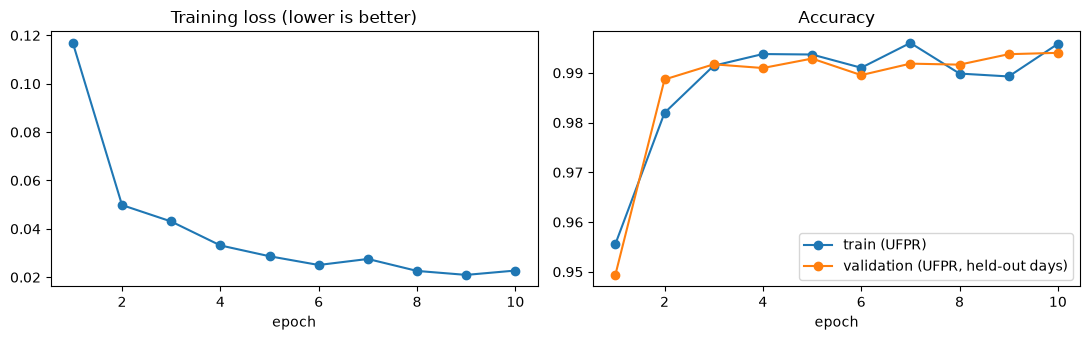

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
epochs = range(1, EPOCHS + 1)
ax1.plot(epochs, history["loss"], marker="o")
ax1.set_title("Training loss (lower is better)")
ax1.set_xlabel("epoch")
ax2.plot(epochs, history["train_acc"], marker="o", label="train (UFPR)")
ax2.plot(epochs, history["val_acc"], marker="o", label="validation (UFPR, held-out days)")
ax2.set_title("Accuracy")
ax2.set_xlabel("epoch")
ax2.legend()
plt.tight_layout()
plt.show()

## 6. The real test: PUCPR, a lot the model has never seen

We load the best saved model and score it on PUCPR **once**.

Besides accuracy, we look at the **confusion matrix**: how many empty spots were called occupied and vice versa.
Those two mistakes matter differently: telling a driver a spot is free when it isn't wastes their time.

In [8]:
model.load_state_dict(torch.load("small_cnn_best.pt"))
model.eval()

predictions = []
with torch.no_grad():
    for i in range(0, len(X_test), 1024):
        predictions.append(model(prepare_batch(X_test[i:i + 1024])).argmax(dim=1).cpu())
predictions = torch.cat(predictions)

test_acc = (predictions == y_test).float().mean().item()
print(f"Validation accuracy (UFPR, held-out days): {best_val:.2%}")
print(f"Test accuracy (PUCPR, never seen):         {test_acc:.2%}")
print()

# Confusion matrix: rows = the truth, columns = what the model said
names = ["empty", "occupied"]
matrix = [[((y_test == t) & (predictions == p)).sum().item() for p in range(2)] for t in range(2)]
print(f"{'':16s}{'said empty':>12s}{'said occupied':>15s}")
for t in range(2):
    print(f"{'truly ' + names[t]:16s}{matrix[t][0]:12d}{matrix[t][1]:15d}")

said_free_but_taken = matrix[1][0] / (matrix[1][0] + matrix[1][1])
said_taken_but_free = matrix[0][1] / (matrix[0][0] + matrix[0][1])
print()
print(f"Occupied spots wrongly called empty: {said_free_but_taken:.1%}")
print(f"Empty spots wrongly called occupied: {said_taken_but_free:.1%}")

Validation accuracy (UFPR, held-out days): 99.40%
Test accuracy (PUCPR, never seen):         94.11%

                  said empty  said occupied
truly empty            52712           4260
truly occupied          1626          41402

Occupied spots wrongly called empty: 3.8%
Empty spots wrongly called occupied: 7.5%


## 7. Look at the mistakes

Numbers tell you *how often* the model is wrong; pictures tell you *why*. Each patch below was misclassified.

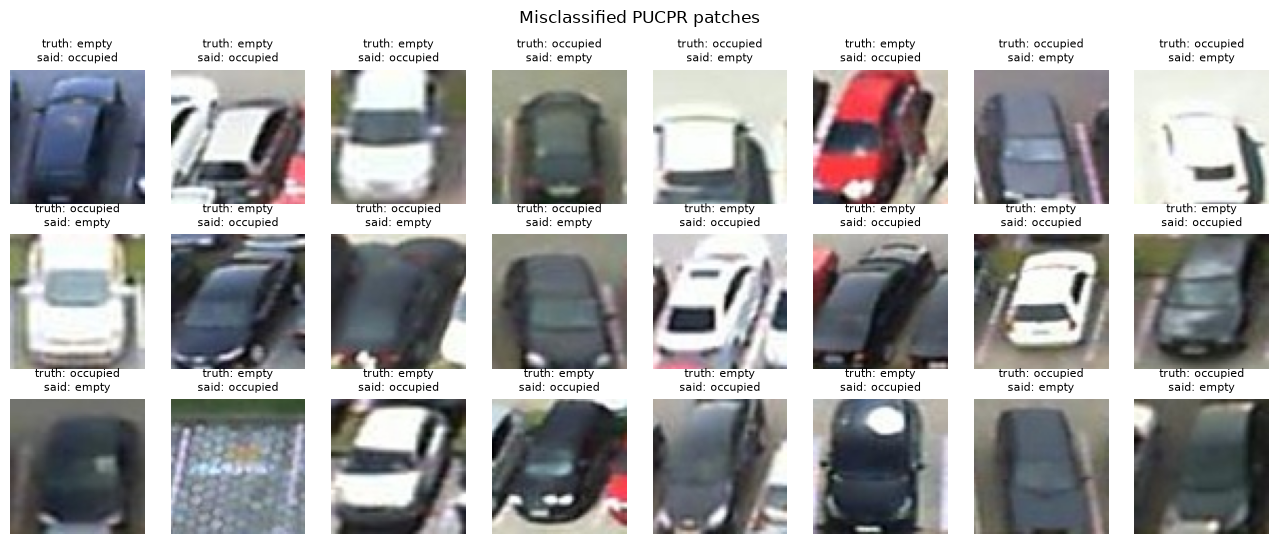

In [9]:
wrong = (predictions != y_test).nonzero().flatten().tolist()
picks = random.sample(wrong, min(24, len(wrong)))

fig, axes = plt.subplots(3, 8, figsize=(13, 5.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, picks):
    ax.imshow(X_test[i].permute(1, 2, 0).numpy())
    ax.set_title(f"truth: {names[y_test[i]]}\nsaid: {names[predictions[i]]}", fontsize=8)
plt.suptitle("Misclassified PUCPR patches")
plt.tight_layout()
plt.show()

## What to write down (fill this in after running)

- Validation accuracy (UFPR): ___
- Test accuracy (PUCPR): ___
- **Generalization gap** (val − test): ___ ← how much the model drops on a new lot
- Which mistake is more common, and what do the misclassified patches have in common?

Compare against the PKLot paper's baseline (~89%), but note it isn't an exact apples-to-apples comparison
(different method and split).

**Next (notebook 04):** a pretrained model (ResNet18). Does starting from a model that has seen millions of
photos shrink the generalization gap?